# **Project Week 1**

## 1. Inspect the derm7pt dataset

In [1]:
import os
import pandas as pd
from derm7pt.dataset import Derm7PtDatasetGroupInfrequent

dir_release = 'release_v0'
derm_data = Derm7PtDatasetGroupInfrequent(
    dir_images=os.path.join(dir_release, 'images'),
    metadata_df=pd.read_csv(os.path.join(dir_release, 'meta/meta.csv')),
    train_indexes=list(pd.read_csv(os.path.join(dir_release, 'meta/train_indexes.csv'))['indexes']),
    valid_indexes=list(pd.read_csv(os.path.join(dir_release, 'meta/valid_indexes.csv'))['indexes']),
    test_indexes=list(pd.read_csv(os.path.join(dir_release, 'meta/test_indexes.csv'))['indexes']))

print(derm_data.df.shape)
print(derm_data.df.columns.tolist())
derm_data.df.head()

(1011, 27)
['case_num', 'diagnosis', 'seven_point_score', 'pigment_network', 'streaks', 'pigmentation', 'regression_structures', 'dots_and_globules', 'blue_whitish_veil', 'vascular_structures', 'level_of_diagnostic_difficulty', 'elevation', 'location', 'sex', 'management', 'clinic', 'derm', 'case_id', 'notes', 'diagnosis_numeric', 'pigment_network_numeric', 'blue_whitish_veil_numeric', 'vascular_structures_numeric', 'pigmentation_numeric', 'streaks_numeric', 'dots_and_globules_numeric', 'regression_structures_numeric']


,case_num,diagnosis,seven_point_score,pigment_network,streaks,pigmentation,regression_structures,dots_and_globules,blue_whitish_veil,vascular_structures,...,case_id,notes,diagnosis_numeric,pigment_network_numeric,blue_whitish_veil_numeric,vascular_structures_numeric,pigmentation_numeric,streaks_numeric,dots_and_globules_numeric,regression_structures_numeric
0,1,basal cell carcinoma,0,absent,absent,absent,absent,absent,absent,arborizing,...,NaN,NaN,0,0,0,1,0,0,0,0
1,2,basal cell carcinoma,1,absent,absent,absent,absent,irregular,absent,absent,...,NaN,NaN,0,0,0,0,0,0,2,0
2,3,basal cell carcinoma,1,absent,absent,absent,absent,irregular,absent,arborizing,...,NaN,NaN,0,0,0,1,0,0,2,0
3,4,basal cell carcinoma,4,absent,absent,absent,blue areas,irregular,present,within regression,...,NaN,NaN,0,0,1,1,0,0,2,1
4,5,basal cell carcinoma,1,absent,absent,diffuse irregular,absent,absent,absent,absent,...,NaN,NaN,0,0,0,0,2,0,0,0


- Each row is lesion abnormal spot or patch on the skin. This could be mole, birthmark etc. Lesions says nothing about the condition yet but the term simply points points out an observed abnormality in the skin. Each row has two belonging images "clinic" and "dermo" dermo being image with higher resolution used for the model

- **Diagnosis** contains the diagnosis in str form

- **Diagnosis_numeric** contains the the diagnosis as numeric label. BCC(0), NEW(1), MEL(2), MISC(3), SK(4)

- **seven_point_score** contains the overall score for the lesion based on the 7 criteria. The score can kinda be abstracted from the values in the other columns like " pigementation" etc. " blue dots". 3 or more means suspiscious for melanoma calls for biopsy.

- **Criterion_numeric** the numeric columns converts the "typical/absent/atypical" into numeric values 0,1,2. This is what CBM model needs to be trained on. 

- The data is already divided into train, test, validation sets


In [2]:
print(derm_data.df.shape)
print(derm_data.df.columns.tolist())

derm_data.dataset_stats()   # train / valid / test sizes

# Class balance of diagnosis and the 7 concepts in the training set
for col in ['diagnosis_numeric', 'pigment_network_numeric', 'blue_whitish_veil_numeric',
            'vascular_structures_numeric', 'pigmentation_numeric', 'streaks_numeric',
            'dots_and_globules_numeric', 'regression_structures_numeric']:
    print(col, derm_data.train[col].value_counts().sort_index().to_dict())

(1011, 27)
['case_num', 'diagnosis', 'seven_point_score', 'pigment_network', 'streaks', 'pigmentation', 'regression_structures', 'dots_and_globules', 'blue_whitish_veil', 'vascular_structures', 'level_of_diagnostic_difficulty', 'elevation', 'location', 'sex', 'management', 'clinic', 'derm', 'case_id', 'notes', 'diagnosis_numeric', 'pigment_network_numeric', 'blue_whitish_veil_numeric', 'vascular_structures_numeric', 'pigmentation_numeric', 'streaks_numeric', 'dots_and_globules_numeric', 'regression_structures_numeric']
Number of cases: 1011
Number of cases to train: 413
Number of cases to validate: 203
Number of cases to test: 395
diagnosis_numeric {0: 19, 1: 256, 2: 90, 3: 32, 4: 16}
pigment_network_numeric {0: 160, 1: 160, 2: 93}
blue_whitish_veil_numeric {0: 339, 1: 74}
vascular_structures_numeric {0: 347, 1: 43, 2: 23}
pigmentation_numeric {0: 253, 1: 44, 2: 116}
streaks_numeric {0: 273, 1: 39, 2: 101}
dots_and_globules_numeric {0: 84, 1: 156, 2: 173}
regression_structures_numeric 

- Unbalanced diagnosis
- All numeric categories will be turned into binary concepts rather than 3 as int he text columns
- The 7 point score can go above 7. Its called 7 point because it 7 criteria. 
- The turn every criteria into binary concept [0,1] and ignore the weighted points of 2 given to some of them

In [3]:
import numpy as np

# 7-point checklist criteria: concept = 1 if the *suspicious* variant is present (score > 0 in derm7pt)
CONCEPTS = {
    'Atypical pigment network':     ('pigment_network_numeric',       [2], 2),
    'Blue-whitish veil':            ('blue_whitish_veil_numeric',     [1], 2),
    'Atypical vascular structures': ('vascular_structures_numeric',   [2], 2),
    'Irregular pigmentation':       ('pigmentation_numeric',          [2], 1),
    'Irregular streaks':            ('streaks_numeric',               [2], 1),
    'Irregular dots/globules':      ('dots_and_globules_numeric',     [2], 1),
    'Regression structures':        ('regression_structures_numeric', [1], 1),
}
CONCEPT_NAMES = list(CONCEPTS)
CLASS_NAMES = ['BCC', 'NEV', 'MEL', 'MISC', 'SK']

df = derm_data.df
C = np.stack([df[col].isin(vals).values for col, vals, _ in CONCEPTS.values()], axis=1).astype(np.float32)
Y = df['diagnosis_numeric'].values.astype(np.int64)

meta = os.path.join(dir_release, 'meta')
split_idx = {s: pd.read_csv(os.path.join(meta, f'{s}_indexes.csv'))['indexes'].values
             for s in ['train', 'valid', 'test']}

# Sanity check: weighted sum of our concepts should reproduce the official 7-point score
weights = np.array([w for _, _, w in CONCEPTS.values()])
match = (C @ weights == df['seven_point_score'].values).mean()
print(f'7-pt score reproduced for {match:.1%} of cases')

print(pd.DataFrame(C[split_idx['train']], columns=CONCEPT_NAMES).mean().round(2).to_string())

7-pt score reproduced for 100.0% of cases
Atypical pigment network        0.23
Blue-whitish veil               0.18
Atypical vascular structures    0.06
Irregular pigmentation          0.28
Irregular streaks               0.24
Irregular dots/globules         0.42
Regression structures           0.23


Not sure what the above cell does

In [4]:
import torch, torchvision
from torchvision import transforms
from PIL import Image
from tqdm import tqdm

IMG_TYPE = 'derm'                      # 'derm' = dermoscopic, 'clinic' = clinical photo
FEAT_FILE = f'features_{IMG_TYPE}_resnet50.npy'
device = 'cuda' if torch.cuda.is_available() else 'cpu'

backbone = torchvision.models.resnet50(weights=torchvision.models.ResNet50_Weights.IMAGENET1K_V2)
backbone.fc = torch.nn.Identity()      # output the 2048-d feature vector instead of ImageNet classes
backbone.eval().to(device)

preprocess = transforms.Compose([
    transforms.Resize(256), transforms.CenterCrop(224), transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])

def load(i):
    img = derm_data.derm_image(i) if IMG_TYPE == 'derm' else derm_data.clinic_image(i)  # crops black border
    return preprocess(Image.fromarray(img))

if os.path.exists(FEAT_FILE):
    X = np.load(FEAT_FILE)
else:
    feats, n, bs = [], len(df), 32
    with torch.no_grad():
        for s in tqdm(range(0, n, bs)):
            batch = torch.stack([load(i) for i in range(s, min(s + bs, n))]).to(device)
            feats.append(backbone(batch).cpu().numpy())
    X = np.concatenate(feats)
    np.save(FEAT_FILE, X)

print(X.shape)   # expect (1011, 2048)

(1011, 2048)


- The above cell  turns every image into 2048 numbers features once

## 2. Build concept bottleneck model

In [5]:
import copy
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, roc_auc_score

In [6]:
class CBM(nn.Module):
    def __init__(self, n_features, n_concepts, n_classes):
        super().__init__()
        self.g = nn.Linear(n_features, n_concepts)   # concept predictor  x -> c
        self.f = nn.Linear(n_concepts, n_classes)    # label predictor    c -> y (linear = interpretable)

    def forward(self, x, c_override=None, mask=None):
        """Returns (concept_logits, concept_probs, class_logits).
        Intervention: where mask==1, the predicted concept prob is replaced by c_override."""
        c_logits = self.g(x)
        c_prob = torch.sigmoid(c_logits)
        if c_override is not None:
            c_prob = torch.where(mask.bool(), c_override, c_prob)
        return c_logits, c_prob, self.f(c_prob)


class BlackBox(nn.Module):
    """Baseline without a bottleneck: x -> y directly."""
    def __init__(self, n_features, n_classes):
        super().__init__()
        self.h = nn.Linear(n_features, n_classes)

    def forward(self, x):
        return self.h(x)

In [7]:
def _t(a, dtype=torch.float32):
    return torch.as_tensor(a, dtype=dtype)


def class_weights(y, n_classes):
    """Inverse-frequency class weights (training set), normalised to mean 1."""
    counts = np.bincount(y, minlength=n_classes).astype(np.float32)
    w = 1.0 / np.maximum(counts, 1)
    return _t(w / w.mean())


def make_data(X, C, Y, split_idx, n_classes):
    """Standardise features with TRAIN statistics only, and pack everything as tensors."""
    tr, va, te = split_idx['train'], split_idx['valid'], split_idx['test']
    mu, sd = X[tr].mean(0), X[tr].std(0) + 1e-6
    Z = (X - mu) / sd
    D = {'n_classes': n_classes}
    for name, idx in [('tr', tr), ('va', va), ('te', te)]:
        D['X' + name] = _t(Z[idx])
        D['C' + name] = _t(C[idx])
        D['Y' + name] = _t(Y[idx], torch.long)
    D['cw_cls'] = class_weights(Y[tr], n_classes)
    return D

In [8]:
def _fit(module, train_loss, val_score, epochs=5000, lr=5e-3, wd=1e-3, patience=300):
    """Full-batch Adam on `module`'s parameters; restores the parameters with the best
    validation score (higher = better). Score = NEGATIVE validation loss (smooth -> reliable stopping)."""
    opt = torch.optim.Adam(module.parameters(), lr=lr, weight_decay=wd)
    best, best_state, since = -np.inf, None, 0
    for ep in range(epochs):
        module.train()
        opt.zero_grad()
        loss = train_loss()
        loss.backward()
        opt.step()
        module.eval()
        with torch.no_grad():
            s = val_score()
        if s > best + 1e-5:
            best, since = s, 0
            best_state = copy.deepcopy(module.state_dict())
        else:
            since += 1
            if since > patience:
                break
    module.load_state_dict(best_state)
    return best

## 3. Setup model so it can be trained with the 3 training regimes

In [9]:
def train_concept_head(model, D):
    """Train g on x -> c (used by independent and sequential). Early stopping: val BCE."""
    loss = lambda: F.binary_cross_entropy_with_logits(model.g(D['Xtr']), D['Ctr'])
    score = lambda: -F.binary_cross_entropy_with_logits(model.g(D['Xva']), D['Cva']).item()
    _fit(model.g, loss, score)


def train_label_head(model, Ctr_input, D, val_concepts):
    """Train f on given concept inputs -> y. Early stopping: val cross-entropy on `val_concepts`."""
    loss = lambda: F.cross_entropy(model.f(Ctr_input), D['Ytr'], weight=D['cw_cls'])
    score = lambda: -F.cross_entropy(model.f(val_concepts), D['Yva'], weight=D['cw_cls']).item()
    _fit(model.f, loss, score)


def train_independent(D, seed=0):
    """g: x -> c.  f: TRUE c -> y.  f only meets predicted concepts at test time."""
    torch.manual_seed(seed)
    m = CBM(D['Xtr'].shape[1], D['Ctr'].shape[1], D['n_classes'])
    train_concept_head(m, D)
    train_label_head(m, D['Ctr'], D, D['Cva'])
    return m


def train_sequential(D, seed=0, concept_model=None):
    """g: x -> c (trained first, then frozen).  f: PREDICTED c -> y."""
    torch.manual_seed(seed)
    m = CBM(D['Xtr'].shape[1], D['Ctr'].shape[1], D['n_classes'])
    if concept_model is not None:                       # reuse the same g as independent (fair comparison)
        m.g.load_state_dict(concept_model.g.state_dict())
    else:
        train_concept_head(m, D)
    with torch.no_grad():
        tr_c = torch.sigmoid(m.g(D['Xtr']))
        val_c = torch.sigmoid(m.g(D['Xva']))
    train_label_head(m, tr_c, D, val_c)
    return m


def train_joint(D, lam=1.0, seed=0):
    """g and f trained together: loss = CE(diagnosis) + lam * BCE(concepts)."""
    torch.manual_seed(seed)
    m = CBM(D['Xtr'].shape[1], D['Ctr'].shape[1], D['n_classes'])

    def joint_loss(split):
        c_logits, _, y_logits = m(D['X' + split])
        return (F.cross_entropy(y_logits, D['Y' + split], weight=D['cw_cls'])
                + lam * F.binary_cross_entropy_with_logits(c_logits, D['C' + split]))

    _fit(m, lambda: joint_loss('tr'), lambda: -joint_loss('va').item())
    return m


def train_blackbox(D, seed=0):
    """Baseline: x -> y directly, no concepts."""
    torch.manual_seed(seed)
    m = BlackBox(D['Xtr'].shape[1], D['n_classes'])
    loss = lambda: F.cross_entropy(m(D['Xtr']), D['Ytr'], weight=D['cw_cls'])
    score = lambda: -F.cross_entropy(m(D['Xva']), D['Yva'], weight=D['cw_cls']).item()
    _fit(m, loss, score)
    return m

In [10]:
def mean_auc(c_true, c_prob):
    aucs = [roc_auc_score(c_true[:, j], c_prob[:, j])
            for j in range(c_true.shape[1]) if 0 < c_true[:, j].sum() < len(c_true)]
    return float(np.mean(aucs))


def label_metrics(y_true, y_pred):
    return {'acc': accuracy_score(y_true, y_pred),
            'bal_acc': balanced_accuracy_score(y_true, y_pred),
            'macro_f1': f1_score(y_true, y_pred, average='macro')}


@torch.no_grad()
def evaluate(model, D, split='te'):
    X, C, Y = D['X' + split], D['C' + split].numpy(), D['Y' + split].numpy()
    model.eval()
    if isinstance(model, BlackBox):
        return label_metrics(Y, model(X).argmax(1).numpy())
    _, c_prob, y_logits = model(X)
    c_prob = c_prob.numpy()
    out = label_metrics(Y, y_logits.argmax(1).numpy())
    out['concept_acc'] = float(((c_prob > 0.5) == C).mean())
    out['concept_auc'] = mean_auc(C, c_prob)
    return out


@torch.no_grad()
def per_concept_auc(model, D, names, split='te'):
    C = D['C' + split].numpy()
    c_prob = torch.sigmoid(model.g(D['X' + split])).numpy()
    return {n: roc_auc_score(C[:, j], c_prob[:, j]) for j, n in enumerate(names)}


@torch.no_grad()
def intervention_curve(model, D, split='te', n_orders=20, seed=0, metric='bal_acc'):
    """Replace k randomly chosen predicted concepts with their TRUE values (k = 0..7),
    averaged over `n_orders` random concept orders (as in the CBM paper)."""
    X, C, Y = D['X' + split], D['C' + split], D['Y' + split].numpy()
    k_max = C.shape[1]
    rng = np.random.default_rng(seed)
    scores = np.zeros((n_orders, k_max + 1))
    for r in range(n_orders):
        order = rng.permutation(k_max)
        for k in range(k_max + 1):
            mask = torch.zeros_like(C)
            mask[:, order[:k]] = 1
            y_pred = model(X, c_override=C, mask=mask)[2].argmax(1).numpy()
            scores[r, k] = label_metrics(Y, y_pred)[metric]
    return scores.mean(0), scores.std(0)

In [11]:
D = make_data(X, C, Y, split_idx, n_classes=len(CLASS_NAMES))

models = {}
models['independent'] = train_independent(D)
models['sequential']  = train_sequential(D, concept_model=models['independent'])  # same g, fair comparison

# Joint: choose lambda on the VALIDATION set
joint_runs = {lam: train_joint(D, lam=lam) for lam in [0.1, 1.0, 10.0]}
for lam, m in joint_runs.items():
    print(f'joint lambda={lam}: val bal_acc = {evaluate(m, D, "va")["bal_acc"]:.3f}')
best_lam = max(joint_runs, key=lambda l: evaluate(joint_runs[l], D, 'va')['bal_acc'])
models[f'joint (λ={best_lam})'] = joint_runs[best_lam]

models['black-box (no concepts)'] = train_blackbox(D)

joint lambda=0.1: val bal_acc = 0.329
joint lambda=1.0: val bal_acc = 0.280
joint lambda=10.0: val bal_acc = 0.254


- the joint model was trained with three values of λ (the weight on the concept loss). Validation balanced accuracy drops steadily as λ grows: 0.33 → 0.28 → 0.25. λ = 0.1 was selected for the test evaluation

- There’s a clear accuracy vs. concept trade-off. The more the model is forced to predict the dermatologist’s concepts correctly, the worse its diagnosis gets

- The selected model barely respects the concepts. Choosing λ by diagnosis accuracy alone automatically picks the smallest λ, the version closest to a black box. This likely explains joint’s high accuracy but poor concept quality and leakage

- “Best λ” depends on the goal. For trustworthy, correctable explanations, a larger λ would be preferable despite lower accuracy. Reporting concept AUC per λ would make this trade-off explicit.

## 4. Assess model performance

In [12]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

results = pd.DataFrame({name: evaluate(m, D, 'te') for name, m in models.items()}).T
display(results.round(3))

,acc,bal_acc,macro_f1,concept_acc,concept_auc
independent,0.377,0.238,0.185,0.618,0.665
sequential,0.233,0.259,0.145,0.618,0.665
joint (λ=0.1),0.451,0.427,0.365,0.540,0.553
black-box (no concepts),0.294,0.374,0.267,NaN,NaN


- on the test set, joint has the best diagnosis performance (balanced accuracy 0.43, macro-F1 0.37), ahead of the black box (0.37) and well ahead of sequential (0.26) and independent (0.24); chance is 0.20. For concepts, the pattern is reversed: independent and sequential (which share the same concept predictor g) reach a concept AUC of 0.67, while joint is close to random at 0.55. Plain accuracy is misleading here, since always predicting “nevus” 
would score 0.55

- Better diagnosis does not come with better concepts. Joint is the most accurate model but has the least correct concepts, so its accuracy must come from something other than the concepts (suspected leakage, tested in the next steps)

- Independent and sequential are held back by noisy concept predictions. Their concepts are better than joint’s but still weak (AUC 0.67), and the diagnosis can only be as good as the concepts it receives

- All models are weak overall. The frozen ImageNet features and only 413 training images limit performance; the joint vs. black-box gap (0.43 vs. 0.37) is too small to trust from a single run on a test set with only 16 BCC and 19 SK cases

In [13]:
concept_models = {k: v for k, v in models.items() if not k.startswith('black')}
display(pd.DataFrame({k: per_concept_auc(m, D, CONCEPT_NAMES) for k, m in concept_models.items()}).round(3))

,independent,sequential,joint (λ=0.1)
Atypical pigment network,0.666,0.666,0.570
Blue-whitish veil,0.694,0.694,0.701
Atypical vascular structures,0.628,0.628,0.488
Irregular pigmentation,0.657,0.657,0.361
Irregular streaks,0.678,0.678,0.666
Irregular dots/globules,0.656,0.656,0.643
Regression structures,0.677,0.677,0.444


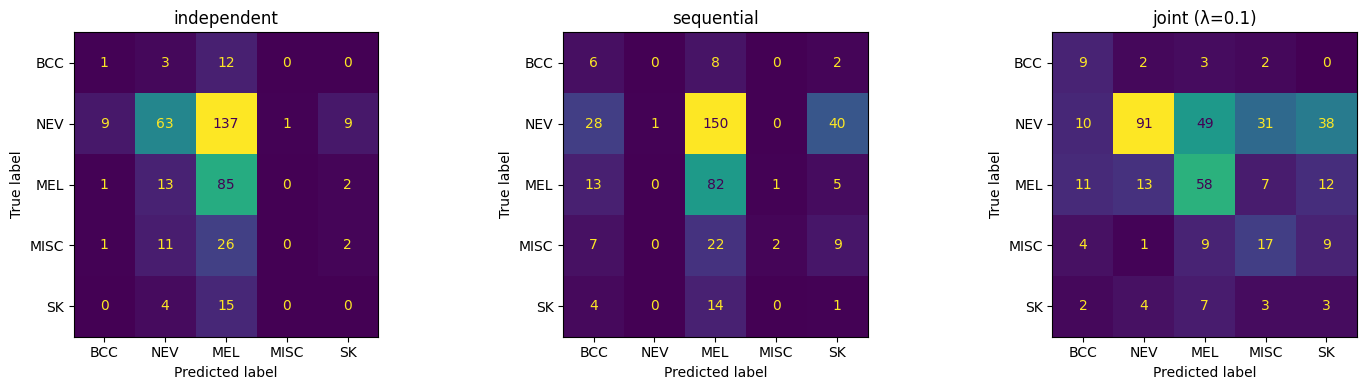

In [14]:
fig, axes = plt.subplots(1, len(concept_models), figsize=(5 * len(concept_models), 4))
for ax, (name, m) in zip(axes, concept_models.items()):
    with torch.no_grad():
        y_pred = m(D['Xte'])[2].argmax(1).numpy()
    ConfusionMatrixDisplay.from_predictions(D['Yte'].numpy(), y_pred, display_labels=CLASS_NAMES,
                                            ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.show()

In [15]:
Yte = D['Yte'].numpy()
print('Test class counts      :', dict(zip(CLASS_NAMES, np.bincount(Yte, minlength=5).tolist())))
print('Always-NEV baseline acc:', round((Yte == 1).mean(), 3))

for name, m in models.items():
    with torch.no_grad():
        out = m(D['Xte'])
        pred = (out if isinstance(m, BlackBox) else out[2]).argmax(1).numpy()
    print(f'{name:28s} predicts:', dict(zip(CLASS_NAMES, np.bincount(pred, minlength=5).tolist())))

print()
for name, m in concept_models.items():
    with torch.no_grad():
        pred = m.f(D['Cte']).argmax(1).numpy()
    print(f'{name:28s} with TRUE concepts:', {k: round(v, 3) for k, v in label_metrics(Yte, pred).items()})

Test class counts      : {'BCC': 16, 'NEV': 219, 'MEL': 101, 'MISC': 40, 'SK': 19}
Always-NEV baseline acc: 0.554
independent                  predicts: {'BCC': 12, 'NEV': 94, 'MEL': 275, 'MISC': 1, 'SK': 13}
sequential                   predicts: {'BCC': 58, 'NEV': 1, 'MEL': 276, 'MISC': 3, 'SK': 57}
joint (λ=0.1)                predicts: {'BCC': 36, 'NEV': 111, 'MEL': 126, 'MISC': 60, 'SK': 62}
black-box (no concepts)      predicts: {'BCC': 53, 'NEV': 72, 'MEL': 66, 'MISC': 59, 'SK': 145}

independent                  with TRUE concepts: {'acc': 0.372, 'bal_acc': 0.456, 'macro_f1': 0.331}
sequential                   with TRUE concepts: {'acc': 0.21, 'bal_acc': 0.164, 'macro_f1': 0.074}
joint (λ=0.1)                with TRUE concepts: {'acc': 0.241, 'bal_acc': 0.218, 'macro_f1': 0.139}


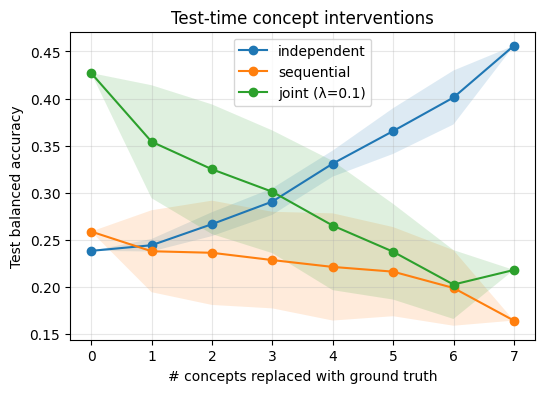

In [16]:
plt.figure(figsize=(6, 4))
for name, m in concept_models.items():
    mean, std = intervention_curve(m, D, n_orders=20)
    ks = np.arange(len(mean))
    plt.plot(ks, mean, marker='o', label=name)
    plt.fill_between(ks, mean - std, mean + std, alpha=0.15)
plt.xlabel('# concepts replaced with ground truth'); plt.ylabel('Test balanced accuracy')
plt.title('Test-time concept interventions'); plt.legend(); plt.grid(alpha=0.3); plt.show()

## 5. Exploratory study of the explanations given by the concepts

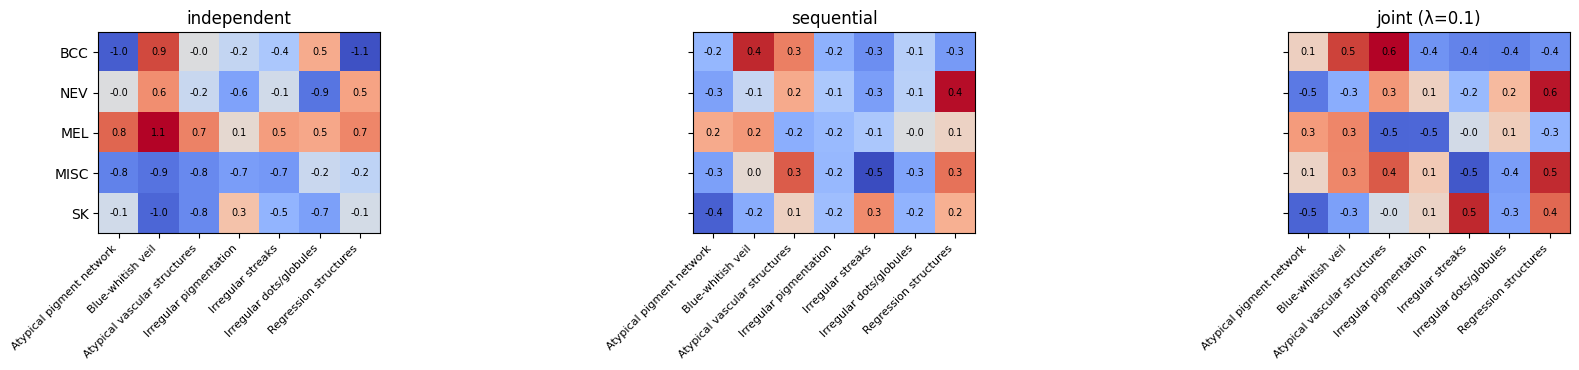

In [17]:
# f's weights: how strongly each concept pushes towards each diagnosis (red = towards, blue = away)
fig, axes = plt.subplots(1, len(concept_models), figsize=(6 * len(concept_models), 3.8), sharey=True)
for ax, (name, m) in zip(axes, concept_models.items()):
    W = m.f.weight.detach().numpy()          # shape (5 diagnoses, 7 concepts)
    v = np.abs(W).max()
    ax.imshow(W, cmap='coolwarm', vmin=-v, vmax=v)
    ax.set_xticks(range(len(CONCEPT_NAMES))); ax.set_xticklabels(CONCEPT_NAMES, rotation=45, ha='right', fontsize=8)
    ax.set_yticks(range(len(CLASS_NAMES))); ax.set_yticklabels(CLASS_NAMES)
    for i in range(W.shape[0]):
        for j in range(W.shape[1]):
            ax.text(j, i, f'{W[i, j]:.1f}', ha='center', va='center', fontsize=7)
    ax.set_title(name)
plt.tight_layout(); plt.show()

In [18]:
rows = {}
for name, m in concept_models.items():
    with torch.no_grad():
        _, p, y_logits = m(D['Xte'])
        soft = label_metrics(Yte, y_logits.argmax(1).numpy())['bal_acc']
        hard = label_metrics(Yte, m.f((p > 0.5).float()).argmax(1).numpy())['bal_acc']   # round to 0/1
    rows[name] = {'bal_acc soft concepts': soft, 'bal_acc hard (0/1) concepts': hard, 'drop': soft - hard}
display(pd.DataFrame(rows).T.round(3))

,bal_acc soft concepts,bal_acc hard (0/1) concepts,drop
independent,0.238,0.236,0.002
sequential,0.259,0.248,0.010
joint (λ=0.1),0.427,0.392,0.035


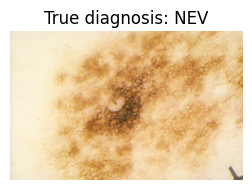

,TRUE,independent,sequential,joint (λ=0.1)
Atypical pigment network,1.0,0.87,0.87,0.46
Blue-whitish veil,0.0,0.08,0.08,0.36
Atypical vascular structures,0.0,0.35,0.35,0.76
Irregular pigmentation,0.0,0.73,0.73,0.27
Irregular streaks,0.0,0.19,0.19,0.16
Irregular dots/globules,0.0,0.99,0.99,0.95
Regression structures,0.0,0.78,0.78,0.71


Predicted diagnosis: {'independent': 'MEL', 'sequential': 'MEL', 'joint (λ=0.1)': 'NEV'}
Independent after correcting concepts: NEV 



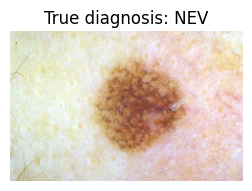

,TRUE,independent,sequential,joint (λ=0.1)
Atypical pigment network,0.0,0.38,0.38,0.38
Blue-whitish veil,0.0,0.40,0.40,0.55
Atypical vascular structures,0.0,0.59,0.59,0.48
Irregular pigmentation,0.0,0.08,0.08,0.70
Irregular streaks,0.0,0.35,0.35,0.13
Irregular dots/globules,0.0,0.57,0.57,0.94
Regression structures,1.0,0.83,0.83,0.76


Predicted diagnosis: {'independent': 'MEL', 'sequential': 'MEL', 'joint (λ=0.1)': 'NEV'}
Independent after correcting concepts: NEV 



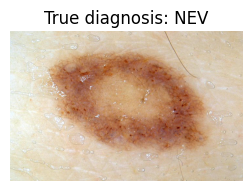

,TRUE,independent,sequential,joint (λ=0.1)
Atypical pigment network,0.0,0.47,0.47,0.73
Blue-whitish veil,0.0,0.64,0.64,0.56
Atypical vascular structures,0.0,0.77,0.77,0.35
Irregular pigmentation,0.0,0.49,0.49,0.23
Irregular streaks,0.0,0.28,0.28,0.19
Irregular dots/globules,0.0,0.11,0.11,0.94
Regression structures,1.0,0.22,0.22,0.55


Predicted diagnosis: {'independent': 'MEL', 'sequential': 'BCC', 'joint (λ=0.1)': 'MEL'}
Independent after correcting concepts: NEV 



In [19]:
te_idx = split_idx['test']
ind = concept_models['independent']
with torch.no_grad():
    pred_before = ind(D['Xte'])[2].argmax(1).numpy()
    pred_after  = ind.f(D['Cte']).argmax(1).numpy()           # after correcting all 7 concepts

# Cases the independent model gets wrong, but gets right once its concepts are corrected
cases = np.where((pred_before != Yte) & (pred_after == Yte))[0][:3]

for i in cases:
    plt.figure(figsize=(3, 3)); plt.imshow(derm_data.derm_image(int(te_idx[i]))); plt.axis('off')
    plt.title(f'True diagnosis: {CLASS_NAMES[Yte[i]]}'); plt.show()

    table = {'TRUE': D['Cte'][i].numpy()}
    diag = {}
    for name, m in concept_models.items():
        with torch.no_grad():
            _, p, y_logits = m(D['Xte'][i:i + 1])
        table[name] = p[0].numpy()
        diag[name] = CLASS_NAMES[y_logits.argmax(1).item()]
    display(pd.DataFrame(table, index=CONCEPT_NAMES).round(2))
    print('Predicted diagnosis:', diag)
    print('Independent after correcting concepts:', CLASS_NAMES[pred_after[i]], '\n')

## 6. Suggest 3 potential use cases of model explanations

- Assuming this is conceptual and general, so our findings or models are not needed to adress this


**Example 1**
- Use case: User is a dermatologitst. They can use it for decision support where the model show hcich checklist criteria it sees, adn the doctor confirms or correct them befor deciding

- Success criterion:
Doctors with the CBM reach higher balanced accuracy than doctors alone or doctors with a black box AI. 
However there are studies that show doctor abilities degrading as a result of use of AI in medical diagnosis.


**Example 2**:
- Use case: User is a medical student. Use case is learning the 7 - point checklist with concept level feedback on each of the 7 criteria. Without the CBM the student looks at the image and gives a diagnosis if wrong labelled wrong they might miss a leanring opportunity. With the CBM tool they can see the presence of the 7 criterias.

- Success criterion:
Students trained with the tool score higher on a checklist test, and agree more with expert annotations than a control group.

**Example 3**:
- Use case:

- Success criterion:


# **Project Week 2**

## *1. Select 2 use cases...*

Select 2 use cases of model explanations for your CBM model, and define associated
explicit success criteria. Here you will want to think about use cases and success
criteria that you are able to assess with the people and resources that you already have.
If your use cases from Part 1 are inappropriate, come up with new ones. Ask your TAs
for help if you need it

**Case 1: Concept correction by a clinician (human corrects model)**

- **Simulation:** A dermatologist receives the model's predicted probabilities for the 7 criteria
  and, due to limited time, checks only the k concepts the model is most uncertain about
  (probability closest to 0.5). Each checked concept is replaced with the dermatologist's
  true annotation, and f recomputes the diagnosis. We compare with checking concepts in
  random order (baseline). The dermatologists' true concept labels in derm7pt play the clinician.

- **Success criteria:**
  1. Diagnostic performance improves as more concepts are corrected.
  2. Most of the gain comes from the first few corrections, and more than with random order.
  3. Corrections rarely turn a correct diagnosis into a wrong one.

- **Metrics:** balanced accuracy vs. k = 0…7 (uncertainty-targeted vs. random order);
  melanoma recall (share of real melanomas detected); help/harm rate (wrong → right vs. right → wrong).

**Case 2: Model double-checks the clinician's concepts (model corrects human)**

- **Simulation:** An inexperienced or non-specialised doctor (e.g. a GP), or a doctor under time
  pressure, fills in the 7-point checklist with some mistakes. We simulate this by flipping
  10% of the true test annotations (0 ↔ 1). The model does not know which ones were flipped:
  for each image, the k concepts where the model's prediction disagrees most with the doctor's
  annotation are replaced by the model's probability, and f recomputes the diagnosis.

- **Comparison:** doctor alone (f on flipped annotations), doctor + model (after replacement),
  perfect doctor (f on true annotations, upper bound).

- **Success criterion:** doctor + model achieves higher diagnostic performance than the doctor
  alone, and in particular misses fewer cancers.

- **Metrics:** balanced accuracy, and the false-negative rate for cancer: the share of malignant
  lesions (MEL + BCC) predicted as benign, since a missed cancer is the worst-case outcome.

## *2. Define quantitative XAI performance...*

Define quantitative XAI performance tasks & metrics that aim to measure how well
your model explanations live up to their success criteria. Identify whether, and to what
extent, these tasks/metrics are proxy measuremen


### Case 1: Concept correction by a clinician
| Task (what we simulate) | Metric | Proxy? |
|---|---|---|
| Correct the k most uncertain concepts (closest to 0.5) with the true annotation | Balanced accuracy vs. k = 0…7 | Yes |
| Same, but in random order (baseline) | Balanced accuracy vs. k; gap to the uncertainty-targeted curve at small k | Yes |
| Correct concepts, then check missed melanomas | Melanoma recall (reported together with balanced accuracy) | Yes |
| Compare predictions before and after correction | Help rate (wrong → right), harm rate (right → wrong) | Yes |

### Case 2: Model double-checks the clinician's concepts
| Task (what we simulate) | Metric | Proxy? |
|---|---|---|
| Flip 10% of true annotations = imperfect doctor; f on these | Balanced accuracy, cancer false-negative rate ("doctor alone") | Yes |
| Replace the k concepts where the model disagrees most with the doctor by the model's probability | Same metrics ("doctor + model"); gain over doctor alone | Yes |
| f on true annotations | Same metrics ("perfect doctor", upper bound) | Reference |

### To what extent are these proxies?
All metrics are proxies: they measure model behaviour in a simulation, not the real use case.

| What we want to know | What we measure instead | What is lost |
|---|---|---|
| A real dermatologist's corrections | True annotations = a perfect clinician | Real clinicians make mistakes and disagree |
| Which concepts a clinician would check | Fixed order: most uncertain first / random | Real attention depends on experience and time |
| Real annotation mistakes (case 2) | Random 10% flips | Real mistakes are systematic and occur on ambiguous images, which makes them harder to detect |
| The clinician's final decision | The model's diagnosis is always accepted | Clinicians can overrule the model |
| Better patient outcomes | Balanced accuracy, melanoma recall, missed cancers | Better metrics do not guarantee better treatment |
| Clinical performance | 395 test images, one dataset, one run | Small rare classes (16 BCC, 19 SK); other clinics and cameras may differ |

**Strength of the proxy:** case 1 is optimistic (a perfect clinician gives an upper bound on the benefit).
Case 2 is optimistic about error detection (random flips are easier to find than real mistakes).
Hence: if the explanations fail in the proxy, they would very likely fail in practice; if they pass,
they *may* help, but this would need a real user study to confirm.

## *3.Carry out a validation...*

Carry out a validation of how well the explanations perform when the model is trained
either with independent, sequential or joint training.

In [20]:
Yte = D['Yte'].numpy()
MALIGNANT = [CLASS_NAMES.index('BCC'), CLASS_NAMES.index('MEL')]   # cancer classes
MEL = CLASS_NAMES.index('MEL')

def diag_metrics(y_true, y_pred):
    """Balanced accuracy + the two cancer-focused metrics."""
    mal = np.isin(y_true, MALIGNANT)
    return {'bal_acc': balanced_accuracy_score(y_true, y_pred),
            'MEL recall': (y_pred[y_true == MEL] == MEL).mean(),                 # share of melanomas found
            'missed cancer rate': (~np.isin(y_pred[mal], MALIGNANT)).mean()}     # cancers predicted as benign

@torch.no_grad()
def concept_probs(m):
    return m(D['Xte'])[1]                                   # predicted concept probabilities, test set

@torch.no_grad()
def diagnose(m, concepts):
    """f applied to a given concept matrix (numpy or tensor) -> predicted class per image."""
    return m.f(torch.as_tensor(concepts, dtype=torch.float32)).argmax(1).numpy()

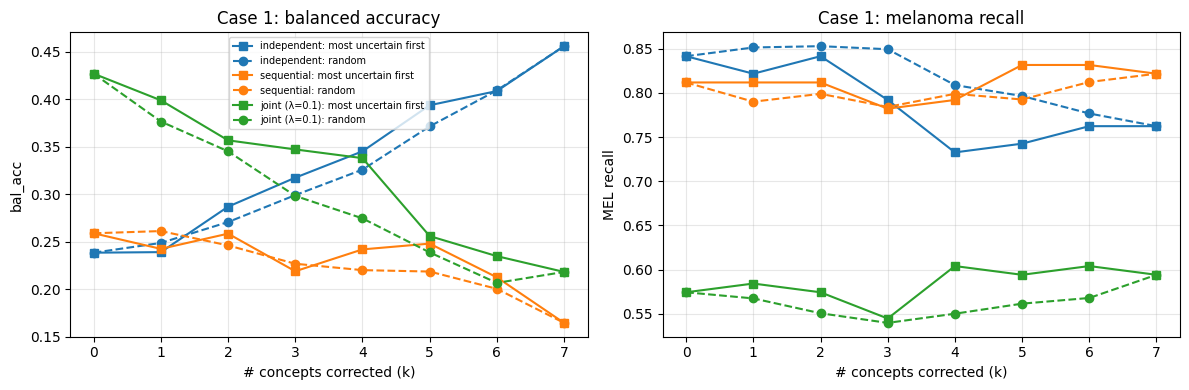

In [21]:
def mask_most_uncertain(p, k):
    """1 for the k concepts closest to 0.5 in each image."""
    mask = torch.zeros_like(p)
    if k > 0:
        mask.scatter_(1, torch.argsort((p - 0.5).abs(), dim=1)[:, :k], 1.0)
    return mask

def mask_random(p, k, rng):
    """1 for k random concepts in each image (a new random choice per image)."""
    order = np.argsort(rng.random(p.shape), axis=1)
    mask = np.zeros(p.shape, dtype=np.float32)
    np.put_along_axis(mask, order[:, :k], 1.0, axis=1)
    return torch.tensor(mask)

def corrected(p, mask):
    return torch.where(mask.bool(), D['Cte'], p)              # replace checked concepts with the true label

rng, K, rows = np.random.default_rng(0), len(CONCEPT_NAMES), []
for name, m in concept_models.items():
    p = concept_probs(m)
    for k in range(K + 1):
        rows.append({'model': name, 'order': 'most uncertain first', 'k': k,
                     **diag_metrics(Yte, diagnose(m, corrected(p, mask_most_uncertain(p, k))))})
        rand = [diag_metrics(Yte, diagnose(m, corrected(p, mask_random(p, k, rng)))) for _ in range(20)]
        rows.append({'model': name, 'order': 'random', 'k': k, **pd.DataFrame(rand).mean().to_dict()})
case1 = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric in zip(axes, ['bal_acc', 'MEL recall']):
    for name in concept_models:
        sub = case1[case1.model == name]
        line, = ax.plot(sub[sub.order == 'most uncertain first'].k, sub[sub.order == 'most uncertain first'][metric],
                        marker='s', label=f'{name}: most uncertain first')
        ax.plot(sub[sub.order == 'random'].k, sub[sub.order == 'random'][metric],
                marker='o', linestyle='--', color=line.get_color(), label=f'{name}: random')
    ax.set_xlabel('# concepts corrected (k)'); ax.set_ylabel(metric); ax.grid(alpha=0.3)
axes[0].set_title('Case 1: balanced accuracy'); axes[1].set_title('Case 1: melanoma recall')
axes[0].legend(fontsize=7); plt.tight_layout(); plt.show()

In [22]:
def help_harm(before, after):
    right = before == Yte
    return {'help (wrong→right)': (after[~right] == Yte[~right]).mean(),
            'harm (right→wrong)': (after[right] != Yte[right]).mean()}

hh = {}
for name, m in concept_models.items():
    p = concept_probs(m)
    before = diagnose(m, p)
    for k in [2, 7]:
        hh[f'{name}, k={k}'] = help_harm(before, diagnose(m, corrected(p, mask_most_uncertain(p, k))))
display(pd.DataFrame(hh).T.round(3))

,help (wrong→right),harm (right→wrong)
"independent, k=2",0.146,0.161
"independent, k=7",0.289,0.490
"sequential, k=2",0.040,0.152
"sequential, k=7",0.043,0.239
"joint (λ=0.1), k=2",0.088,0.258
"joint (λ=0.1), k=7",0.226,0.742


In [23]:
m = concept_models['independent']
p = concept_probs(m)
before = diagnose(m, p)
after = diagnose(m, corrected(p, mask_most_uncertain(p, 7)))
harmed = (before == Yte) & (after != Yte)
print('Harmed cases:', harmed.sum())
print('...originally predicted as:', dict(zip(CLASS_NAMES, np.bincount(before[harmed], minlength=5).tolist())))
print('...avg # wrong concepts before correction:',
      ((p[harmed] > 0.5).float() != D['Cte'][harmed]).sum(1).float().mean().item())

Harmed cases: 73
...originally predicted as: {'BCC': 0, 'NEV': 55, 'MEL': 18, 'MISC': 0, 'SK': 0}
...avg # wrong concepts before correction: 1.8356164693832397


In [ ]:
# case 2
@torch.no_grad()
def case2_run(name, m, flip_rate, seed):
    rng = np.random.default_rng(seed)
    C_true = D['Cte'].numpy()
    flipped = rng.random(C_true.shape) < flip_rate                       # the doctor's (unknown) mistakes
    C_doc = np.where(flipped, 1 - C_true, C_true).astype(np.float32)     # imperfect doctor's annotations
    
    p = concept_probs(m).numpy()

    # The model doesn't know which are wrong: it replaces the entries where it disagrees most with
    # the doctor. Budget = as many entries as the expected number of mistakes.
    disagreement = np.abs(p - C_doc)
    n_replace = int(round(flip_rate * disagreement.size))
    replaced = np.zeros(disagreement.size, dtype=bool)
    replaced[np.argsort(-disagreement.ravel())[:n_replace]] = True
    replaced = replaced.reshape(disagreement.shape)
    C_doc_model = np.where(replaced, p, C_doc).astype(np.float32)

    out = []
    for setting, conc in [('doctor alone', C_doc), ('doctor + model', C_doc_model),
                          ('perfect doctor', C_true), ('model alone', p)]:
        rec = {'model': name, 'flip rate': flip_rate, 'setting': setting, **diag_metrics(Yte, diagnose(m, conc))}
        if setting == 'doctor + model':
            rec['replacements that fixed a real mistake'] = flipped[replaced].mean()
        out.append(rec)
    return out

records = []
for name, m in concept_models.items():
    for fr in [0.1, 0.2, 0.3]:
        for seed in range(10):                                           # average over 10 random sets of mistakes
            records += case2_run(name, m, fr, seed)
case2 = pd.DataFrame(records).groupby(['model', 'flip rate', 'setting'], sort=False).mean().reset_index()

cols = ['doctor alone', 'doctor + model', 'perfect doctor', 'model alone']
for metric in ['bal_acc', 'missed cancer rate']:
    print(metric)
    display(case2.pivot_table(index=['model', 'flip rate'], columns='setting', values=metric)[cols].round(3))

print('Share of the model\'s replacements that fixed a real mistake (random = flip rate)')
display(case2[case2.setting == 'doctor + model'].pivot_table(
    index='model', columns='flip rate', values='replacements that fixed a real mistake').round(3))

bal_acc


setting                  doctor alone  doctor + model  perfect doctor  \
model         flip rate                                                 
independent   0.1               0.379           0.349           0.456   
              0.2               0.315           0.285           0.456   
              0.3               0.270           0.260           0.456   
joint (λ=0.1) 0.1               0.185           0.264           0.218   
              0.2               0.190           0.344           0.218   
              0.3               0.199           0.383           0.218   
sequential    0.1               0.188           0.217           0.164   
              0.2               0.201           0.244           0.164   
              0.3               0.205           0.258           0.164   

setting                  model alone  
model         flip rate               
independent   0.1              0.238  
              0.2              0.238  
              0.3              0.238  
joint (λ=0.1) 0.1              0.427  
              0.2              0.427  
              0.3              0.427  
sequential    0.1              0.259  
              0.2              0.259  
              0.3              0.259

missed cancer rate


setting                  doctor alone  doctor + model  perfect doctor  \
model         flip rate                                                 
independent   0.1               0.157           0.117           0.171   
              0.2               0.175           0.144           0.171   
              0.3               0.161           0.158           0.171   
joint (λ=0.1) 0.1               0.449           0.351           0.359   
              0.2               0.492           0.298           0.359   
              0.3               0.549           0.300           0.359   
sequential    0.1               0.118           0.109           0.085   
              0.2               0.158           0.118           0.085   
              0.3               0.198           0.136           0.085   

setting                  model alone  
model         flip rate               
independent   0.1              0.154  
              0.2              0.154  
              0.3              0.154  
joint (λ=0.1) 0.1              0.308  
              0.2              0.308  
              0.3              0.308  
sequential    0.1              0.068  
              0.2              0.068  
              0.3              0.068

Share of the model's replacements that fixed a real mistake (random = flip rate)


flip rate,0.1,0.2,0.3
model,,,
independent,0.182,0.327,0.444
joint (λ=0.1),0.137,0.251,0.360
sequential,0.182,0.327,0.444


## *4. Critically discuss what ...*

Critically discuss what conclusions you can draw from the carried out validation with
respect to the model explanations’ capabilities. Be clear about what you can conclude
and what you cannot conclude. Do you learn anything about the model from the
explanations, given your validation of those explanation

# **Poster**